# Drag breakdown: parasite vs. induced

Sizes the plane from `base.json` (`run_pipeline`, OpenVSP drag) and splits its drag into
- **parasite** $D_0 = q\,S\,C_{D_0}$ (independent of lift) and
- **induced** $D_i = q\,S\,\dfrac{C_L^2}{\pi e\,AR}$ (drag due to lift),

the same parabolic polar the mission model uses.

1. Drag vs. speed at cruise altitude, with the cruise point and the minimum-drag speed ($L/D_{max}$).
2. Share of parasite drag at the start of cruise (MTOW), the end of cruise (tank empty) and at the stall speed with flaps.

In [6]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

import ardea_sizer as az
from ardea_sizer._constants import G, CRUISE_ALTITUDE, FIELD_ALTITUDE
from ardea_sizer.physics import get_isa_density, get_c_l_max_3d

base = az.load("../base.json")
plane, base = az.run_pipeline(base)

a, m = base.assumptions, base.mission
S, AR, E = float(plane.wing_area), float(plane.aspect_ratio), a.oswald_eff
CD0 = float(plane.c_d_0)
K = 1 / (np.pi * E * AR)  # induced drag factor: CDi = K * CL^2
MTOW, FUEL = float(plane.mtow), float(plane.fuel_mass)
RHO_CRUISE = get_isa_density(altitude=CRUISE_ALTITUDE)
RHO_FIELD = get_isa_density(altitude=FIELD_ALTITUDE)


def drag(v, lift, rho):
    # (parasite, induced) drag [N] and CL at speed v [m/s] for a given lift [N]
    q = 0.5 * rho * v**2
    c_l = lift / (q * S)
    return q * S * CD0, q * S * K * c_l**2, c_l

Run 1: c_d_0_wing 0.00950 -> 0.00824   f_fixed 0.00540 -> 0.00624 m^2   CD0 0.01892 -> 0.01914   S 0.5730 m^2   fuel 6.628 kg
Run 2: c_d_0_wing 0.00824 -> 0.00824   f_fixed 0.00624 -> 0.00624 m^2   CD0 0.01909 -> 0.01909   S 0.5752 m^2   fuel 6.711 kg


## Where we sit

Lift at stall includes the tail down-force used for the wing sizing, so the stall CL is the flapped $C_{L,max}$.

In [7]:
CASES = {
    "Cruise start (MTOW)":     (m.cruise_speed, MTOW * G, RHO_CRUISE),
    "Cruise end (tank empty)": (m.cruise_speed, (MTOW - FUEL) * G, RHO_CRUISE),
    "Stall, flaps (MTOW)":     (m.stall_speed, MTOW * G + base.tail.downforce, RHO_FIELD),
}

rows = []
for name, (v, lift, rho) in CASES.items():
    d_0, d_i, c_l = drag(v, lift, rho)
    rows.append({
        "condition": name,
        "V [km/h]": v * 3.6,
        "CL": c_l,
        "CD0": CD0,
        "CDi": K * c_l**2,
        "parasite [N]": d_0,
        "induced [N]": d_i,
        "total [N]": d_0 + d_i,
        "parasite [%]": 100 * d_0 / (d_0 + d_i),
        "L/D": lift / (d_0 + d_i),
    })
table = pd.DataFrame(rows).set_index("condition")
table.round({"V [km/h]": 0, "CL": 3, "CD0": 5, "CDi": 5, "parasite [N]": 2, "induced [N]": 2,
             "total [N]": 2, "parasite [%]": 1, "L/D": 2})

,V [km/h],CL,CD0,CDi,parasite [N],induced [N],total [N],parasite [%],L/D
condition,,,,,,,,,
Cruise start (MTOW),300.0,0.087,0.01909,0.00038,44.25,0.87,45.12,98.1,4.46
Cruise end (tank empty),300.0,0.058,0.01909,0.00017,44.25,0.39,44.65,99.1,3.03
"Stall, flaps (MTOW)",72.0,1.559,0.01909,0.12094,2.58,16.33,18.91,13.6,11.14


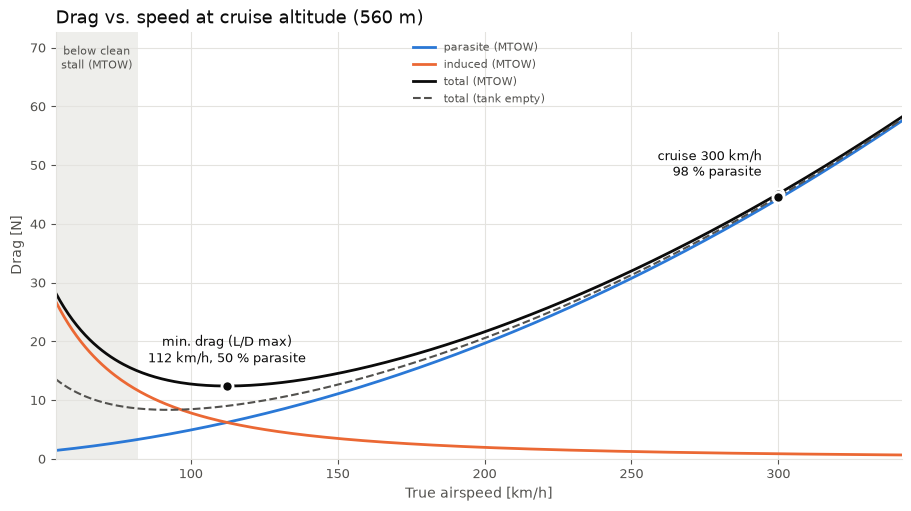

In [8]:
INK, INK_MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e4e3df", "#ffffff"
PARASITE, INDUCED = "#2a78d6", "#eb6834"


def style(ax):
    ax.grid(color=GRID, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(colors=INK_MUTED, labelsize=9)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)
    for side in ("left", "bottom"):
        ax.spines[side].set_color(GRID)


# drag vs. speed at cruise altitude
v = np.linspace(15, 95, 400)
d_0, d_i, _ = drag(v, MTOW * G, RHO_CRUISE)
d_0_end, d_i_end, _ = drag(v, (MTOW - FUEL) * G, RHO_CRUISE)
v_md = np.sqrt(2 * MTOW * G / (RHO_CRUISE * S)) * (K / CD0) ** 0.25  # minimum drag: D0 = Di
v_stall_clean = np.sqrt(2 * MTOW * G / (RHO_CRUISE * S * get_c_l_max_3d(c_l_max_2d=a.c_l_max_2d_cruise)))

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)
ax.axvspan(v[0] * 3.6, v_stall_clean * 3.6, color=GRID, alpha=0.6, lw=0, zorder=0)
ax.annotate("below clean\nstall (MTOW)", (0.5 * (v[0] + v_stall_clean) * 3.6, 0.97), xycoords=("data", "axes fraction"),
            ha="center", va="top", color=INK_MUTED, fontsize=8)

ax.plot(v * 3.6, d_0, color=PARASITE, lw=2, label="parasite (MTOW)")
ax.plot(v * 3.6, d_i, color=INDUCED, lw=2, label="induced (MTOW)")
ax.plot(v * 3.6, d_0 + d_i, color=INK, lw=2, label="total (MTOW)")
ax.plot(v * 3.6, d_0_end + d_i_end, color=INK_MUTED, lw=1.5, ls="--", label="total (tank empty)")

for name in ("Cruise start (MTOW)", "Cruise end (tank empty)"):
    r = table.loc[name]
    ax.plot(r["V [km/h]"], r["total [N]"], "o", ms=8, color=INK, mec=SURFACE, mew=2, zorder=4)
r = table.loc["Cruise start (MTOW)"]
ax.annotate(f"cruise {r['V [km/h]']:.0f} km/h\n{r['parasite [%]']:.0f} % parasite",
            (r["V [km/h]"], r["total [N]"]), xytext=(-12, 10), textcoords="offset points",
            ha="right", va="bottom", color=INK, fontsize=9)
d_md = sum(drag(v_md, MTOW * G, RHO_CRUISE)[:2])
ax.plot(v_md * 3.6, d_md, "o", ms=8, color=INK, mec=SURFACE, mew=2, zorder=4)
ax.annotate(f"min. drag (L/D max)\n{v_md * 3.6:.0f} km/h, 50 % parasite", (v_md * 3.6, d_md),
            xytext=(0, 14), textcoords="offset points", ha="center", va="bottom", color=INK, fontsize=9)

ax.set_ylim(0, 1.25 * float((d_0 + d_i)[-1]))
ax.set_xlim(v[0] * 3.6, v[-1] * 3.6)
ax.set_xlabel("True airspeed [km/h]", color=INK_MUTED)
ax.set_ylabel("Drag [N]", color=INK_MUTED)
ax.set_title(f"Drag vs. speed at cruise altitude ({CRUISE_ALTITUDE:.0f} m)", color=INK, fontsize=13, loc="left")
ax.legend(frameon=False, fontsize=8, labelcolor=INK_MUTED, loc="upper center")
style(ax)
plt.show()

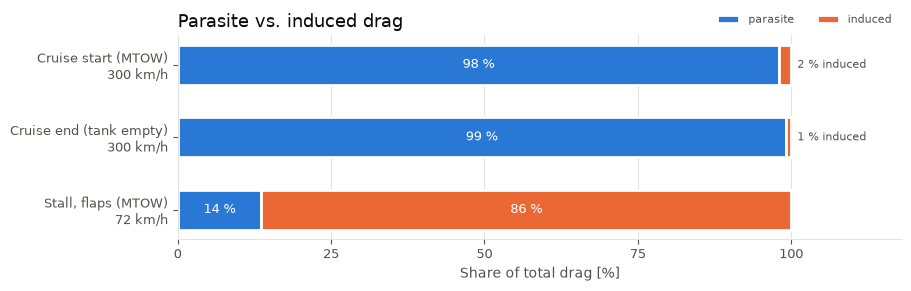

In [9]:
# share of parasite vs. induced drag in each condition
fig, ax = plt.subplots(figsize=(9, 2.8), constrained_layout=True)
names = list(table.index)[::-1]
par = table.loc[names, "parasite [%]"].to_numpy()
ind = 100 - par
y = np.arange(len(names))
ax.barh(y, par, height=0.55, color=PARASITE, edgecolor=SURFACE, linewidth=2, label="parasite")
ax.barh(y, ind, left=par, height=0.55, color=INDUCED, edgecolor=SURFACE, linewidth=2, label="induced")
for yi, p, i in zip(y, par, ind):
    if p >= 8:
        ax.text(p / 2, yi, f"{p:.0f} %", ha="center", va="center", color=SURFACE, fontsize=9)
    if i >= 8:
        ax.text(p + i / 2, yi, f"{i:.0f} %", ha="center", va="center", color=SURFACE, fontsize=9)
    else:  # too thin for a label inside
        ax.text(101, yi, f"{i:.0f} % induced", ha="left", va="center", color=INK_MUTED, fontsize=8)
ax.set_yticks(y, [f"{n}\n{table.loc[n, 'V [km/h]']:.0f} km/h" for n in names])
ax.set_xlim(0, 118)
ax.set_xticks([0, 25, 50, 75, 100])
ax.set_xlabel("Share of total drag [%]", color=INK_MUTED)
ax.set_title("Parasite vs. induced drag", color=INK, fontsize=13, loc="left")
ax.legend(frameon=False, fontsize=8, labelcolor=INK_MUTED, ncols=2, loc="lower right", bbox_to_anchor=(1, 1))
style(ax)
ax.grid(axis="y", visible=False)
plt.show()

**Limits at stall.** The polar uses the clean $C_{D_0}$ and $e$ from cruise. With flaps down the parasite drag is
higher (flap profile drag, typically $\Delta C_{D_0} \approx 0.01 \dots 0.05$ depending on type and deflection), the span
loading of a part-span flap lowers $e$, and near $C_{L,max}$ the profile drag rises with $C_L$. So at stall both parts are
underestimated and the parasite share shown is only indicative; the stall row is for orientation, not for performance.